# IT3212 Assignment 3: Predicting student dropout and academic success

**Dataset:** *Predict Students' Dropout and Academic Success* (UCI ML Repository, 4,424 records,
34 features, 3 classes). Each record is one student at a Portuguese higher-education institution,
described at the moment of enrolment plus their results over the first two semesters.

## 1. Problem statement

**Real-world problem.** Roughly a third of the students in this dataset never finish their degree.
Dropout is expensive for the student (debt, lost years) and for the institution (lost funding,
worse completion statistics). Institutions already hold the administrative and academic data
needed to see it coming, but a counsellor cannot read 4,000 student records by hand every
semester. What the institution needs is a way to decide *who to contact first*, early enough that
an intervention (tutoring, a payment plan, a change of course) can still change the outcome.

**Machine-learning problem.** Supervised multi-class classification. Given 34 features known by
the end of the first academic year, predict the final status of a student:

| Class | Count | Share |
|---|---|---|
| Graduate | 2,209 | 49.9 % |
| Dropout | 1,421 | 32.1 % |
| Enrolled (still studying) | 794 | 17.9 % |

**Connecting the two.** The institution's cost is asymmetric: missing a student who then drops out
is far more costly than contacting a student who would have graduated anyway. The classes are also
unbalanced, and the smallest class (*Enrolled*) is the most ambiguous one, since those students
have not yet reached an outcome. Plain accuracy would therefore reward a model that ignores the
minority class, so we report **macro-averaged F1** as the headline metric (it weights all three
classes equally) alongside accuracy and the per-class F1 scores.

In [1]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import (train_test_split, cross_val_score, GridSearchCV,
                                     StratifiedKFold)
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, mutual_info_classif, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier,
                              AdaBoostClassifier, HistGradientBoostingClassifier)
from sklearn.metrics import (f1_score, accuracy_score, classification_report,
                             ConfusionMatrixDisplay)
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

data = pd.read_csv("graduation_dataset.csv")
print("shape:", data.shape)
print("missing values:", int(data.isna().sum().sum()), "| duplicate rows:", int(data.duplicated().sum()))
data.head()

shape: (4424, 35)
missing values: 0 | duplicate rows: 0


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,6,1,11,1,1,1,1,3,4,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,5,1,1,1,22,27,10,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,8,2,15,1,1,1,23,27,6,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,12,1,3,0,1,1,22,28,10,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


## 2. Preprocessing and its justification

The dataset is already clean: **no missing values and no duplicate rows**, so imputation and
de-duplication are not needed. What does need attention is the *encoding*: nine columns are
categorical codes that happen to be stored as integers.

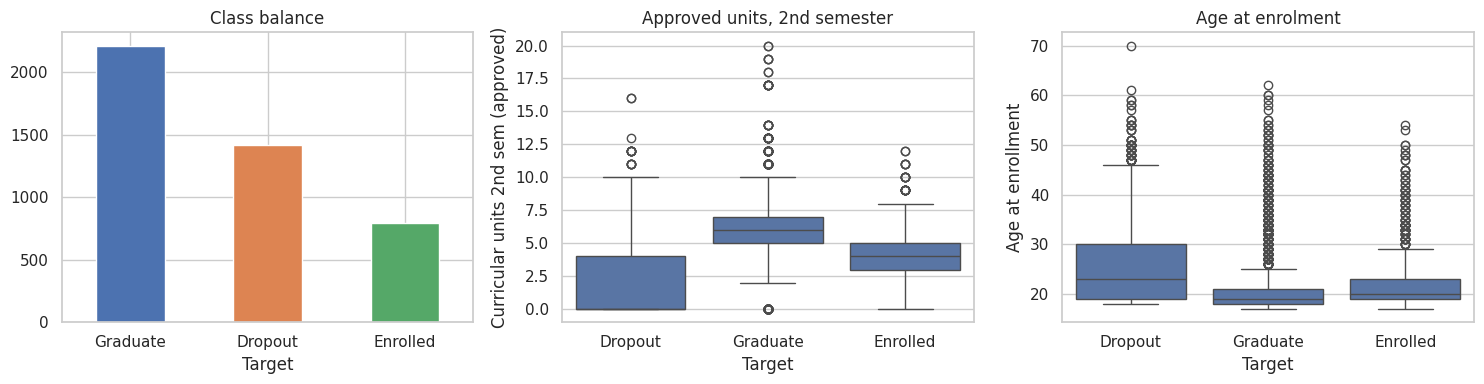

Target
Graduate    0.499
Dropout     0.321
Enrolled    0.179


In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
data["Target"].value_counts().plot.bar(ax=axes[0], color=["#4c72b0", "#dd8452", "#55a868"])
axes[0].set_title("Class balance"); axes[0].tick_params(axis="x", rotation=0)

sns.boxplot(data=data, x="Target", y="Curricular units 2nd sem (approved)", ax=axes[1])
axes[1].set_title("Approved units, 2nd semester")

sns.boxplot(data=data, x="Target", y="Age at enrollment", ax=axes[2])
axes[2].set_title("Age at enrolment")
plt.tight_layout(); plt.savefig("fig_eda.pdf", bbox_inches="tight"); plt.show()

print(data["Target"].value_counts(normalize=True).round(3).to_string())

Columns such as `Course`, `Application mode`, `Nacionality` and the parents' qualification and
occupation codes are **nominal**: code 7 is not "greater than" code 3, and the gaps between codes
carry no meaning. Left as integers they would mislead every distance-based or linear model, so
they are one-hot encoded.

Several of them have a long tail of very rare levels (`Father's occupation` has 46 levels for
4,424 rows). One-hot encoding each of those would add columns that fire a handful of times, which
invites overfitting, so levels holding **less than 1 % of the rows are grouped into a single
"other" level** before encoding.

The remaining steps:

* **Binary flags** (`Debtor`, `Gender`, `Scholarship holder`, …) are already 0/1 and are left alone.
* **Standardisation** is applied inside every pipeline, fitted on the training fold only, because
  KNN, SVM and the neural network all compare distances or rely on gradient scaling. Tree models
  do not need it but are unaffected by it.
* **Stratified 80/20 train/test split**, so the class proportions are preserved and the minority
  class is represented in both halves.
* **Class weights** are used wherever the estimator supports them, to stop the models from ignoring
  the *Enrolled* minority.

In [3]:
NOMINAL = ["Marital status", "Application mode", "Course", "Previous qualification",
           "Nacionality", "Mother's qualification", "Father's qualification",
           "Mother's occupation", "Father's occupation"]

def encode(df, rare_threshold=0.01):
    '''One-hot the nominal codes, pooling levels below `rare_threshold` into "other" (-1).'''
    d = df.copy()
    for col in NOMINAL:
        share = d[col].value_counts(normalize=True)
        keep = share[share >= rare_threshold].index
        d[col] = np.where(d[col].isin(keep), d[col], -1)
    return pd.get_dummies(d, columns=NOMINAL, prefix=NOMINAL, dtype=float)

print("nominal levels before pooling:",
      {c: data[c].nunique() for c in NOMINAL})

nominal levels before pooling: {'Marital status': 6, 'Application mode': 18, 'Course': 17, 'Previous qualification': 17, 'Nacionality': 21, "Mother's qualification": 29, "Father's qualification": 34, "Mother's occupation": 32, "Father's occupation": 46}


## 3. Feature extraction and its justification

The raw table stores the academic record as **counts**: units credited, enrolled, evaluated and
approved, per semester. A count on its own is ambiguous. Four approved units is excellent for a
student enrolled in five and poor for a student enrolled in ten. The information the counsellor
actually uses is the *ratio*, and the *direction of travel* between the two semesters.

We therefore derive eleven features:

| Feature | Definition | Why |
|---|---|---|
| `approval_rate_1st`, `approval_rate_2nd` | approved / enrolled | normalises the count by workload |
| `approval_rate_mean`, `approved_total` | summary over both semesters | overall standing |
| `approval_trend` | 2nd − 1st approval rate | a falling trend is the warning sign |
| `grade_mean`, `grade_trend` | mean and change of semester grades | level and direction |
| `eval_per_unit_1st/2nd` | evaluations / enrolled | retakes and extra attempts |
| `zero_approved_any` | passed nothing in a semester | a hard, highly predictive flag |
| `financial_risk` | debtor + unpaid tuition | the two money signals combined |

These are **domain-driven combinations of existing columns**, not new measurements, so they add no
data-collection cost and cannot leak information from the future beyond what the raw columns
already contain.

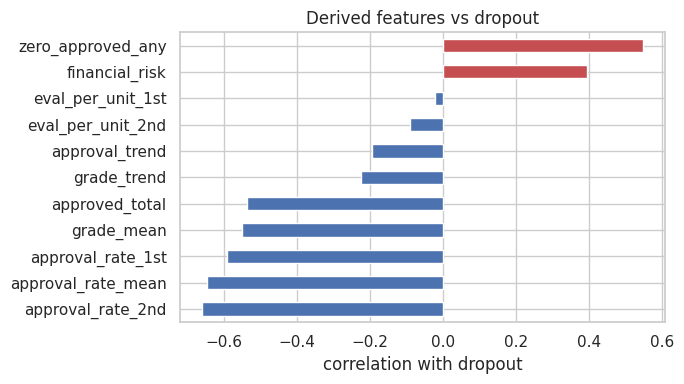

approval_rate_2nd    -0.659
approval_rate_mean   -0.647
approval_rate_1st    -0.591
grade_mean           -0.551
approved_total       -0.537
grade_trend          -0.225
approval_trend       -0.193
eval_per_unit_2nd    -0.089
eval_per_unit_1st    -0.022
financial_risk        0.394
zero_approved_any     0.548


In [4]:
def engineer(df):
    d = df.copy()
    for sem in ("1st", "2nd"):
        enr = d[f"Curricular units {sem} sem (enrolled)"]
        app = d[f"Curricular units {sem} sem (approved)"]
        ev  = d[f"Curricular units {sem} sem (evaluations)"]
        d[f"approval_rate_{sem}"] = np.where(enr > 0, app / enr.replace(0, np.nan), 0.0)
        d[f"eval_per_unit_{sem}"] = np.where(enr > 0, ev / enr.replace(0, np.nan), 0.0)
    d["approved_total"] = (d["Curricular units 1st sem (approved)"]
                           + d["Curricular units 2nd sem (approved)"])
    d["approval_rate_mean"] = d[["approval_rate_1st", "approval_rate_2nd"]].mean(axis=1)
    d["approval_trend"] = d["approval_rate_2nd"] - d["approval_rate_1st"]
    d["grade_mean"] = d[["Curricular units 1st sem (grade)",
                         "Curricular units 2nd sem (grade)"]].mean(axis=1)
    d["grade_trend"] = (d["Curricular units 2nd sem (grade)"]
                        - d["Curricular units 1st sem (grade)"])
    d["zero_approved_any"] = ((d["Curricular units 1st sem (approved)"] == 0)
                              | (d["Curricular units 2nd sem (approved)"] == 0)).astype(int)
    d["financial_risk"] = d["Debtor"] + (1 - d["Tuition fees up to date"])
    return d.fillna(0.0)

eng = engineer(data)
DERIVED = [c for c in eng.columns if c not in data.columns]

corr = eng[DERIVED].corrwith((data["Target"] == "Dropout").astype(int)).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
corr.plot.barh(ax=ax, color=np.where(corr > 0, "#c44e52", "#4c72b0"))
ax.set_xlabel("correlation with dropout"); ax.set_title("Derived features vs dropout")
plt.tight_layout(); plt.savefig("fig_derived.pdf", bbox_inches="tight"); plt.show()
print(corr.round(3).to_string())

The strongest single raw column correlates about −0.57 with dropout; `approval_rate_2nd` reaches
**−0.66**, and `zero_approved_any` **+0.55**. The ratios carry more signal than the counts they
are built from, which is the justification for the step.

## 4. Feature selection and dimensionality reduction

After one-hot encoding we have 116 columns for 4,424 rows. That is wide enough to ask whether
reduction helps, so we **measured it** rather than assuming. Each representation is scored with
the same neutral probe (multinomial logistic regression) under 5-fold stratified cross-validation
on the training set.

encoded: (4424, 116)


            representation  macro_f1    std
          all 116 features    0.7029 0.0170
mutual information, top 20    0.6678 0.0239
mutual information, top 40    0.6935 0.0139
mutual information, top 60    0.6921 0.0121
        PCA, 10 components    0.6358 0.0225
        PCA, 20 components    0.6690 0.0253
        PCA, 40 components    0.6805 0.0238
  random-forest importance    0.6778 0.0155


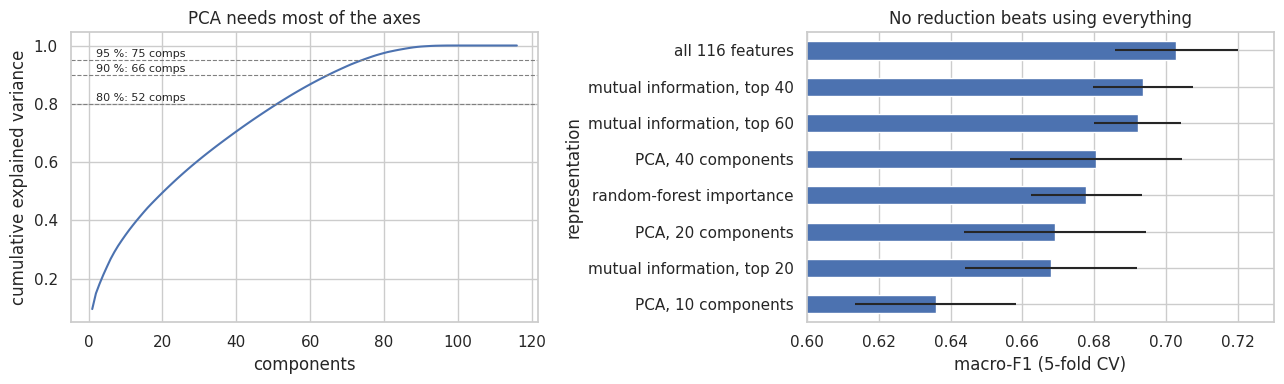

In [5]:
X = encode(eng.drop(columns="Target"))
y = data["Target"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
probe = LogisticRegression(max_iter=2000, random_state=SEED)
print("encoded:", X.shape)

def probe_score(steps):
    pipe = make_pipeline(StandardScaler(), *steps, probe)
    s = cross_val_score(pipe, X_tr, y_tr, cv=cv, scoring="f1_macro", n_jobs=-1)
    return s.mean(), s.std()

candidates = {
    "all 116 features": [],
    "mutual information, top 20": [SelectKBest(mutual_info_classif, k=20)],
    "mutual information, top 40": [SelectKBest(mutual_info_classif, k=40)],
    "mutual information, top 60": [SelectKBest(mutual_info_classif, k=60)],
    "PCA, 10 components": [PCA(n_components=10, random_state=SEED)],
    "PCA, 20 components": [PCA(n_components=20, random_state=SEED)],
    "PCA, 40 components": [PCA(n_components=40, random_state=SEED)],
    "random-forest importance": [SelectFromModel(
        RandomForestClassifier(300, random_state=SEED, n_jobs=-1))],
}
sel = pd.DataFrame([{"representation": k, "macro_f1": m, "std": s}
                    for k, (m, s) in ((k, probe_score(v)) for k, v in candidates.items())])
print(sel.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

var = PCA(random_state=SEED).fit(StandardScaler().fit_transform(X_tr)).explained_variance_ratio_
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(np.arange(1, len(var) + 1), var.cumsum())
for t in (0.8, 0.9, 0.95):
    axes[0].axhline(t, ls="--", lw=.8, color="grey")
    axes[0].annotate(f"{int(t*100)} %: {int(np.searchsorted(var.cumsum(), t) + 1)} comps",
                     (2, t + .01), fontsize=8)
axes[0].set_xlabel("components"); axes[0].set_ylabel("cumulative explained variance")
axes[0].set_title("PCA needs most of the axes")
sel.sort_values("macro_f1").plot.barh(x="representation", y="macro_f1", ax=axes[1],
                                      xerr="std", legend=False, color="#4c72b0")
axes[1].set_xlim(0.6, 0.73); axes[1].set_xlabel("macro-F1 (5-fold CV)")
axes[1].set_title("No reduction beats using everything")
plt.tight_layout(); plt.savefig("fig_selection.pdf", bbox_inches="tight"); plt.show()

**Decision: keep all 116 features.** The measurements justify it:

* **PCA actively hurts** (0.68 at 40 components against 0.70 for the full set). PCA builds dense
  linear mixtures of the inputs, which destroys the axis-aligned sparse structure that the one-hot
  dummies and the tree splits depend on. It also needs **75 of 116 components to reach 95 % of the
  variance**, so there is no low-rank structure to exploit in the first place.
* **Mutual-information selection ties but does not win**: the top 60 features score the same as all
  116. This is a reasonable *efficiency* choice (half the width for the same score) and we report it,
  but it buys no accuracy.
* **Random-forest importance selection is slightly worse** (0.678).

The assignment asks us to justify not using the techniques if we skip them, and this is the
justification: we applied all three, measured them under identical cross-validation, and none
improved on the full feature set. With 4,424 rows against 116 columns the sample-to-feature ratio
is about 38:1, which is comfortable enough that reduction is not required.

## 5. Three algorithms and the justification for choosing them

From the seven options we pick three that **fail in different ways**, so that the comparison in
section 6 is informative rather than three variations on one idea:

* **K-nearest neighbours** — instance-based, no training, a purely local decision. It is the
  natural control: if a simple "students like this one" lookup works, nothing more is needed.
  It is also the one we expect to suffer most from 116 mostly-sparse dimensions.
* **Decision tree** — rule-based and axis-aligned. It handles the mixed categorical/numeric data
  natively, needs no scaling, and most importantly it is the only one of the three a student
  counsellor can read and act on. In a setting where a human must justify contacting a student,
  that matters.
* **SVM with an RBF kernel** — margin-based and global. It can bend a non-linear boundary through
  a high-dimensional space, which is where we expect the best raw performance, at the cost of
  being a black box and the slowest to predict.

Each is tuned by grid search with the same 5-fold stratified cross-validation on the training set;
the test set is touched only once, at the end.

In [6]:
GRIDS = {
    "KNN": (KNeighborsClassifier(),
            {"clf__n_neighbors": [15, 25, 35, 51], "clf__weights": ["uniform", "distance"]}),
    "Decision tree": (DecisionTreeClassifier(random_state=SEED),
            {"clf__max_depth": [4, 6, 8, 12, None], "clf__min_samples_leaf": [1, 5, 20]}),
    "SVM (RBF)": (SVC(kernel="rbf", random_state=SEED),
            {"clf__C": [1, 3, 10, 30], "clf__gamma": ["scale", 0.01, 0.003]}),
}

base_models, base_rows = {}, []
for name, (est, grid) in GRIDS.items():
    pipe = Pipeline([("scale", StandardScaler()), ("clf", est)])
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="f1_macro", n_jobs=-1)
    t0 = time.perf_counter(); gs.fit(X_tr, y_tr); search_s = time.perf_counter() - t0
    pred = gs.best_estimator_.predict(X_te)
    base_models[name] = gs.best_estimator_
    base_rows.append(dict(model=name, best_params=str(gs.best_params_),
                          cv_f1=gs.best_score_,
                          test_f1=f1_score(y_te, pred, average="macro"),
                          test_acc=accuracy_score(y_te, pred), search_s=search_s))
    print(f"{name}: best {gs.best_params_}")

base = pd.DataFrame(base_rows)
print()
print(base[["model", "cv_f1", "test_f1", "test_acc", "search_s"]]
      .to_string(index=False, float_format=lambda v: f"{v:.4f}"))

KNN: best {'clf__n_neighbors': 15, 'clf__weights': 'distance'}


Decision tree: best {'clf__max_depth': 4, 'clf__min_samples_leaf': 1}


SVM (RBF): best {'clf__C': 3, 'clf__gamma': 0.003}

        model  cv_f1  test_f1  test_acc  search_s
          KNN 0.5764   0.5503    0.6746    1.1658
Decision tree 0.6909   0.6775    0.7458    1.8003
    SVM (RBF) 0.7078   0.6885    0.7661   16.3230


## 6. Comparing the three, and explaining the result

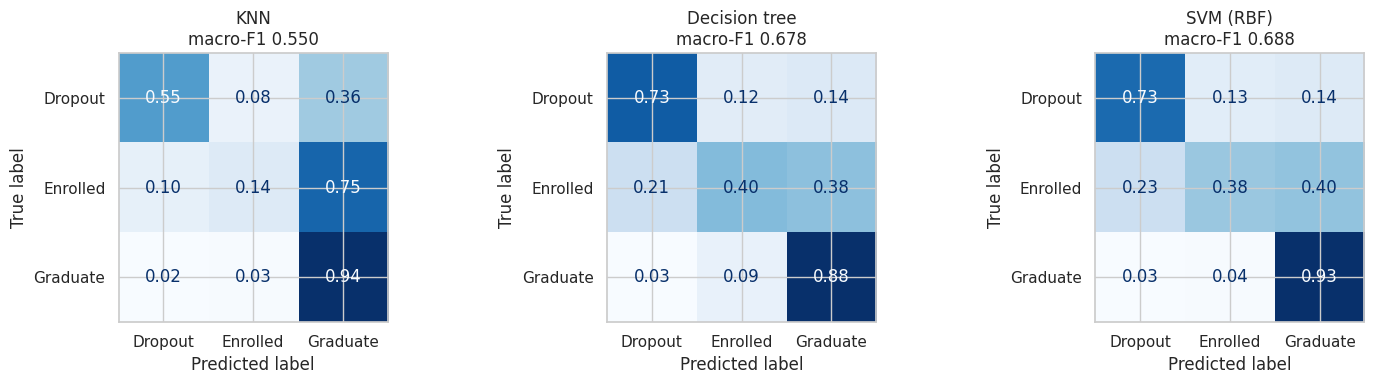


=== KNN ===
              precision    recall  f1-score   support

     Dropout      0.853     0.553     0.671       284
    Enrolled      0.377     0.145     0.209       159
    Graduate      0.652     0.943     0.771       442

    accuracy                          0.675       885
   macro avg      0.627     0.547     0.550       885
weighted avg      0.667     0.675     0.638       885


=== Decision tree ===
              precision    recall  f1-score   support

     Dropout      0.816     0.732     0.772       284
    Enrolled      0.457     0.403     0.428       159
    Graduate      0.792     0.878     0.833       442

    accuracy                          0.746       885
   macro avg      0.688     0.671     0.678       885
weighted avg      0.739     0.746     0.740       885


=== SVM (RBF) ===


              precision    recall  f1-score   support

     Dropout      0.805     0.729     0.765       284
    Enrolled      0.531     0.377     0.441       159
    Graduate      0.798     0.930     0.859       442

    accuracy                          0.766       885
   macro avg      0.711     0.679     0.688       885
weighted avg      0.752     0.766     0.754       885



In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, model) in zip(axes, base_models.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_te, y_te, ax=ax, colorbar=False,
                                          normalize="true", values_format=".2f",
                                          cmap="Blues")
    ax.set_title(f"{name}\nmacro-F1 {f1_score(y_te, model.predict(X_te), average='macro'):.3f}")
plt.tight_layout(); plt.savefig("fig_base_confusion.pdf", bbox_inches="tight"); plt.show()

for name, model in base_models.items():
    print(f"\n=== {name} ===")
    print(classification_report(y_te, model.predict(X_te), digits=3))

**SVM (0.689 macro-F1) > decision tree (0.678) > KNN (0.550).**

*Why KNN collapses.* After one-hot encoding, most of the 116 dimensions are sparse binary dummies.
Euclidean distance over such a space is dominated by how many rare categories two students happen
to share, not by their academic record, and in high dimensions all pairwise distances concentrate
towards the same value. The confusion matrix shows the consequence: KNN recovers only **14 % of
the *Enrolled* students** and defaults to the majority class.

*Why the tree does well for its size.* Grid search chose **depth 4** out of options up to
unlimited. A tree with 31 nodes and four levels of questions gets within 0.01 macro-F1 of the SVM.
That tells us the signal is concentrated in a few threshold rules on the approval rates, exactly
the features engineered in section 3. It also means the problem does not need a complex model,
which is useful because this is the one model a counsellor can read.

*The common failure.* Every model is weakest on *Enrolled* (F1 0.21 to 0.44). This is not a
modelling defect but a property of the label: a student still enrolled has **not yet reached an
outcome**, so their features genuinely look like a mixture of the students who will graduate and
those who will leave. The class is both the smallest and the least separable, and it is the reason
we report macro-F1 rather than accuracy.

## 7. Bagging and boosting

The two ensemble families fix **different errors**, so the base learner has to be chosen to match,
and that is the justification for the pairings below.

* **Bagging** averages many models trained on bootstrap resamples. Averaging cancels *variance*,
  so the base learner should be **high-variance and low-bias**: a fully grown, unpruned decision
  tree, which on its own memorises the training set and changes shape if a few rows move. We also
  include a **random forest**, which is bagging plus random feature subsampling at each split, to
  show the effect of decorrelating the trees further.
* **Boosting** fits models in sequence, each one on the errors of the last. The correction only
  works if each step is a *weak* learner, so the base model should be **low-variance and
  high-bias**: a depth-2 stump that underfits badly alone. We use **AdaBoost** on such stumps and
  **histogram gradient boosting** as a stronger modern variant.
* As a **counter-example** we bag Gaussian naive Bayes, a stable high-bias learner. Theory predicts
  bagging it does nothing, because there is no variance to cancel; we include it to test that.

In [8]:
ENSEMBLES = {
    "Bagging (unpruned trees)": BaggingClassifier(
        DecisionTreeClassifier(random_state=SEED), n_estimators=300,
        random_state=SEED, n_jobs=-1),
    "Random forest": RandomForestClassifier(300, random_state=SEED, n_jobs=-1),
    "Bagging (Gaussian NB)": BaggingClassifier(
        GaussianNB(), n_estimators=300, random_state=SEED, n_jobs=-1),
    "AdaBoost (depth-2)": AdaBoostClassifier(
        DecisionTreeClassifier(max_depth=2, random_state=SEED),
        n_estimators=300, learning_rate=0.5, random_state=SEED),
    "Hist gradient boosting": HistGradientBoostingClassifier(
        max_iter=300, learning_rate=0.1, random_state=SEED),
}

ens_models, ens_rows = {}, []
for name, model in ENSEMBLES.items():
    pipe = Pipeline([("scale", StandardScaler()), ("clf", model)])
    s = cross_val_score(pipe, X_tr, y_tr, cv=cv, scoring="f1_macro", n_jobs=-1)
    t0 = time.perf_counter(); pipe.fit(X_tr, y_tr); fit_s = time.perf_counter() - t0
    pred = pipe.predict(X_te)
    ens_models[name] = pipe
    ens_rows.append(dict(model=name, cv_f1=s.mean(),
                         test_f1=f1_score(y_te, pred, average="macro"),
                         test_acc=accuracy_score(y_te, pred), fit_s=fit_s))

ens = pd.DataFrame(ens_rows)
print(ens.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

                   model  cv_f1  test_f1  test_acc  fit_s
Bagging (unpruned trees) 0.6943   0.7031    0.7684 6.7768
           Random forest 0.6931   0.7084    0.7842 1.2379
   Bagging (Gaussian NB) 0.2856   0.3118    0.3141 0.8789
      AdaBoost (depth-2) 0.7096   0.6799    0.7503 4.0137
  Hist gradient boosting 0.7071   0.6850    0.7525 4.4713


The predictions match the theory.

* **Bagging the unpruned tree lifts it from 0.678 to 0.703** macro-F1. A single unpruned tree
  overfits; 300 of them on different resamples average that instability away.
* **The random forest is the best of the ensembles** (0.708). Subsampling features at each split
  decorrelates the trees, so their errors cancel more completely than plain bagging.
* **Bagging Gaussian naive Bayes collapses to 0.31.** This confirms the reasoning above: NB is
  stable, so every bootstrap replica is nearly the same model and averaging changes nothing. Its
  conditional-independence assumption is also badly violated here, since the one-hot dummies of one
  categorical column are mutually exclusive by construction. Bagging cannot repair bias.
* **Boosting scores highest in cross-validation (0.710) but lower on the test set (0.68).** The
  sequential fitting chases the hardest rows, which on this noisy minority class means chasing
  label ambiguity. AdaBoost in particular stops after only a handful of stumps, so the ensemble
  stays small.

## 8. Basic vs bagging vs boosting vs transfer

Three of the four are in hand. **Transfer learning needs a comment**: there is no publicly
pretrained model for this tabular schema, so transfer in the sense used for images or text does
not apply here. The closest honest analogue is **pretraining on a related task built from the same
features**, so we pretrain a network on the easier binary question "will this student drop out?",
freeze the first block, and fine-tune the trunk for the three-class problem. Section 9 builds it,
and section 10 compares all four families in one table.

## 9. Deep neural network with hyperparameter tuning

A convolutional network is not appropriate here: convolution exploits *spatial or temporal
locality*, and our 116 columns have no such ordering, so neighbouring columns share nothing.
We therefore use a **fully connected deep network**, and tune it.

**Hyperparameters searched and why each one:**

| Hyperparameter | Values | What it controls |
|---|---|---|
| Hidden layer sizes | (64,32), (128,64), (256,128,64) | capacity: can the model represent the boundary without memorising 2,831 rows |
| Dropout | 0.0, 0.3 | regularisation: the main defence against overfitting a small tabular set |
| Learning rate | 1e-3, 3e-4 | optimisation stability of Adam |

Fixed by reasoning rather than search: **ReLU** activations (standard, no vanishing gradient),
**batch normalisation** after each hidden layer (keeps the scale of activations stable so a larger
learning rate is usable), **softmax** output with sparse categorical cross-entropy (three mutually
exclusive classes), **early stopping** with `restore_best_weights` on a held-out validation split,
and **balanced class weights** so the *Enrolled* minority is not ignored.

In [9]:
import keras
from keras import layers
keras.utils.set_random_seed(SEED)

le = LabelEncoder()
Xn = X.to_numpy(dtype="float32"); yn = le.fit_transform(y)
Xn_tr, Xn_te, yn_tr, yn_te = train_test_split(Xn, yn, test_size=0.2, stratify=yn,
                                              random_state=SEED)
Xn_tr, Xn_va, yn_tr, yn_va = train_test_split(Xn_tr, yn_tr, test_size=0.2, stratify=yn_tr,
                                              random_state=SEED)
nsc = StandardScaler().fit(Xn_tr)
Xn_tr, Xn_va, Xn_te = nsc.transform(Xn_tr), nsc.transform(Xn_va), nsc.transform(Xn_te)
weights = dict(enumerate(compute_class_weight("balanced", classes=np.unique(yn_tr), y=yn_tr)))
print("train/val/test:", Xn_tr.shape, Xn_va.shape, Xn_te.shape)
print("class weights:", {le.classes_[k]: round(v, 2) for k, v in weights.items()})

def build(hidden, dropout, lr, n_out=3):
    m = keras.Sequential([keras.Input(shape=(Xn_tr.shape[1],))])
    for h in hidden:
        m.add(layers.Dense(h, activation="relu"))
        m.add(layers.BatchNormalization())
        if dropout:
            m.add(layers.Dropout(dropout))
    m.add(layers.Dense(n_out, activation="softmax"))
    m.compile(optimizer=keras.optimizers.Adam(lr),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def fit_nn(model, xt, yt, xv, yv, cw=None, epochs=200):
    return model.fit(xt, yt, validation_data=(xv, yv), epochs=epochs, batch_size=64,
                     class_weight=cw, verbose=0,
                     callbacks=[keras.callbacks.EarlyStopping(
                         "val_loss", patience=25, restore_best_weights=True)])

search = []
for hidden in [(64, 32), (128, 64), (256, 128, 64)]:
    for dropout in [0.0, 0.3]:
        for lr in [1e-3, 3e-4]:
            keras.utils.set_random_seed(SEED)
            m = build(hidden, dropout, lr)
            h = fit_nn(m, Xn_tr, yn_tr, Xn_va, yn_va, weights)
            search.append(dict(hidden=str(hidden), dropout=dropout, lr=lr,
                               params=m.count_params(), epochs=len(h.history["loss"]),
                               val_f1=f1_score(yn_va, m.predict(Xn_va, verbose=0).argmax(1),
                                               average="macro")))
search = pd.DataFrame(search).sort_values("val_f1", ascending=False)
print(search.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

I0000 00:00:1793127448.264698   12179 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793127448.308901   12179 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793127450.055549   12179 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


train/val/test: (2831, 116) (708, 116) (885, 116)
class weights: {'Dropout': np.float64(1.04), 'Enrolled': np.float64(1.86), 'Graduate': np.float64(0.67)}


        hidden  dropout     lr  params  epochs  val_f1
      (64, 32)   0.3000 0.0003   10051      85  0.7297
      (64, 32)   0.3000 0.0010   10051      44  0.7261
(256, 128, 64)   0.3000 0.0010   73091      30  0.7201
     (128, 64)   0.3000 0.0010   24195      33  0.7176
     (128, 64)   0.3000 0.0003   24195      51  0.7163
(256, 128, 64)   0.3000 0.0003   73091      35  0.7157
      (64, 32)   0.0000 0.0010   10051      30  0.7103
     (128, 64)   0.0000 0.0010   24195      29  0.6960
      (64, 32)   0.0000 0.0003   10051      42  0.6954
(256, 128, 64)   0.0000 0.0010   73091      29  0.6887
(256, 128, 64)   0.0000 0.0003   73091      31  0.6804
     (128, 64)   0.0000 0.0003   24195      33  0.6801


best configuration: (64, 32) dropout 0.3 lr 0.0003


Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_40 (Dense)                │ (None, 64)             │         7,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_28          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_29          │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_42 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,771 (116.30 KB)

 Trainable params: 9,859 (38.51 KB)

 Non-trainable params: 192 (768.00 B)

 Optimizer params: 19,720 (77.04 KB)

training time 20.4s over 85 epochs
              precision    recall  f1-score   support

     Dropout      0.820     0.708     0.760       284
    Enrolled      0.427     0.604     0.500       159
    Graduate      0.855     0.803     0.828       442

    accuracy                          0.737       885
   macro avg      0.701     0.705     0.696       885
weighted avg      0.767     0.737     0.747       885



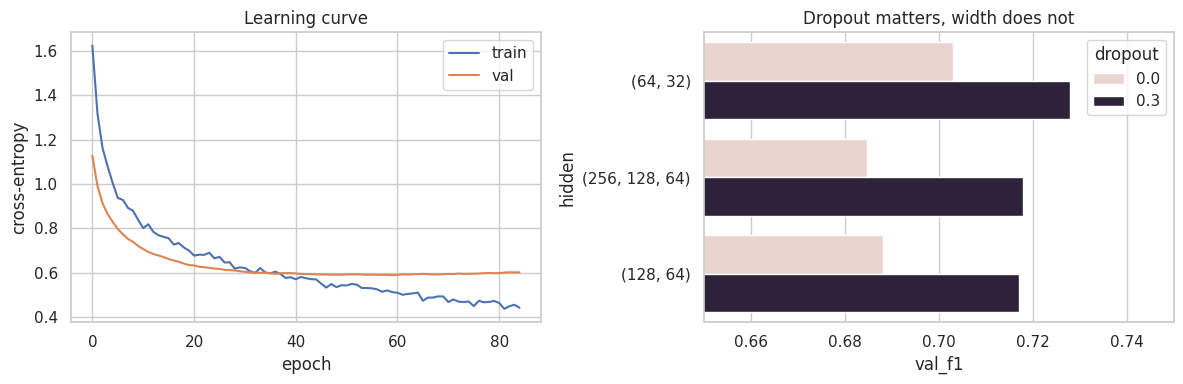

In [10]:
best = search.iloc[0]
hidden = eval(best["hidden"]); dropout = float(best["dropout"]); lr = float(best["lr"])
print("best configuration:", hidden, "dropout", dropout, "lr", lr)

keras.utils.set_random_seed(SEED)
dnn = build(hidden, dropout, lr)
t0 = time.perf_counter(); hist = fit_nn(dnn, Xn_tr, yn_tr, Xn_va, yn_va, weights)
dnn_fit = time.perf_counter() - t0
dnn_pred = dnn.predict(Xn_te, verbose=0).argmax(1)
dnn.summary()
print(f"training time {dnn_fit:.1f}s over {len(hist.history['loss'])} epochs")
print(classification_report(yn_te, dnn_pred, target_names=le.classes_, digits=3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist.history["loss"], label="train"); axes[0].plot(hist.history["val_loss"], label="val")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("cross-entropy"); axes[0].legend()
axes[0].set_title("Learning curve")
sns.barplot(data=search, x="val_f1", y="hidden", hue="dropout", ax=axes[1], errorbar=None)
axes[1].set_xlim(0.65, 0.75); axes[1].set_title("Dropout matters, width does not")
plt.tight_layout(); plt.savefig("fig_nn.pdf", bbox_inches="tight"); plt.show()

In [11]:
# Transfer: pretrain on the binary "dropout vs rest" task, then fine-tune on three classes.
keras.utils.set_random_seed(SEED)
dropout_id = list(le.classes_).index("Dropout")
pre = build(hidden, dropout, lr, n_out=2)
t0 = time.perf_counter()
fit_nn(pre, Xn_tr, (yn_tr == dropout_id).astype(int), Xn_va, (yn_va == dropout_id).astype(int))
pretrain_s = time.perf_counter() - t0

trunk = keras.Sequential(pre.layers[:-1])
for layer in trunk.layers[:2]:
    layer.trainable = False                     # freeze the first block
transfer = keras.Sequential([trunk, layers.Dense(3, activation="softmax")])
transfer.compile(optimizer=keras.optimizers.Adam(lr),
                 loss="sparse_categorical_crossentropy", metrics=["accuracy"])
t0 = time.perf_counter(); fit_nn(transfer, Xn_tr, yn_tr, Xn_va, yn_va, weights)
finetune_s = time.perf_counter() - t0
transfer_pred = transfer.predict(Xn_te, verbose=0).argmax(1)
print(f"pretrain {pretrain_s:.1f}s + fine-tune {finetune_s:.1f}s")
print(classification_report(yn_te, transfer_pred, target_names=le.classes_, digits=3))

pretrain 15.6s + fine-tune 14.8s
              precision    recall  f1-score   support

     Dropout      0.841     0.690     0.758       284
    Enrolled      0.414     0.648     0.505       159
    Graduate      0.854     0.778     0.814       442

    accuracy                          0.727       885
   macro avg      0.703     0.705     0.692       885
weighted avg      0.771     0.727     0.741       885



**The search result is the interesting part: the smallest network wins.** `(64, 32)` with dropout
0.3 reaches the best validation macro-F1, and the 73,000-parameter network does no better than the
10,000-parameter one. Dropout is worth about +0.03 macro-F1 at every width, while width itself is
worth nothing. With 2,831 training rows the model runs out of data long before it runs out of
capacity, which matches what section 4 found: the useful structure in this problem is small.

**Class weights change the trade-off rather than the total.** The network reaches the best
*Enrolled* recall of any model (0.60 against 0.38 for the random forest) by deliberately
sacrificing overall accuracy. For the real-world problem, where missing a future dropout costs
more than a redundant phone call, that is the direction you want to err in.

**Transfer gives nothing here** (0.692 against 0.696 for the plain network). That is the expected
result and worth stating plainly: the pretraining task is built from the same 116 features and the
same 2,831 students, so it introduces no new information. Transfer learning pays off when the
pretrained model has seen data you do not have, which is not the case for a single tabular dataset.

## 10. Complexity, computation time and performance

The comparisons so far were unfair in one respect: the neural network used balanced class weights
while the scikit-learn models did not. For the final table **every model that supports class
weighting gets it**, so the only differences left are the algorithms themselves. We also record
what each model *costs*: the size of the fitted object, the time to fit it, and the time to score
885 test students.

In [12]:
def complexity(model):
    if hasattr(model, "tree_"):
        return f"{model.tree_.node_count} nodes"
    if hasattr(model, "estimators_"):
        trees = [e for e in np.ravel(model.estimators_) if hasattr(e, "tree_")]
        if trees:
            return f"{len(trees)} trees / {sum(t.tree_.node_count for t in trees):,} nodes"
        return f"{len(np.ravel(model.estimators_))} estimators"
    if hasattr(model, "support_vectors_"):
        return f"{len(model.support_vectors_):,} support vectors"
    if isinstance(model, KNeighborsClassifier):
        return f"{len(X_tr):,} stored rows"
    return "-"

FINAL = {
    "KNN (k=15)": KNeighborsClassifier(15, weights="distance"),
    "Decision tree (depth 4)": DecisionTreeClassifier(max_depth=4, random_state=SEED,
                                                      class_weight="balanced"),
    "SVM RBF (C=3)": SVC(C=3, gamma=0.003, random_state=SEED, class_weight="balanced"),
    "Bagging (unpruned trees)": BaggingClassifier(
        DecisionTreeClassifier(random_state=SEED, class_weight="balanced"),
        n_estimators=300, random_state=SEED, n_jobs=-1),
    "Random forest": RandomForestClassifier(300, random_state=SEED, n_jobs=-1,
                                            class_weight="balanced"),
    "AdaBoost (depth-2)": AdaBoostClassifier(
        DecisionTreeClassifier(max_depth=2, random_state=SEED, class_weight="balanced"),
        n_estimators=300, learning_rate=0.5, random_state=SEED),
    "Hist gradient boosting": HistGradientBoostingClassifier(
        max_iter=300, random_state=SEED, class_weight="balanced"),
}

rows = []
for name, model in FINAL.items():
    pipe = Pipeline([("scale", StandardScaler()), ("clf", model)])
    t0 = time.perf_counter(); pipe.fit(X_tr, y_tr); fit_s = time.perf_counter() - t0
    t0 = time.perf_counter(); pred = pipe.predict(X_te); pred_ms = (time.perf_counter() - t0) * 1000
    per = f1_score(y_te, pred, average=None, labels=["Dropout", "Enrolled", "Graduate"])
    rows.append(dict(model=name, accuracy=accuracy_score(y_te, pred),
                     macro_f1=f1_score(y_te, pred, average="macro"),
                     f1_dropout=per[0], f1_enrolled=per[1], f1_graduate=per[2],
                     fit_s=fit_s, predict_ms=pred_ms,
                     complexity=complexity(pipe.named_steps["clf"])))

for name, pred, fit_s in (("Deep NN (64-32, dropout .3)", dnn_pred, dnn_fit),
                          ("Transfer NN", transfer_pred, pretrain_s + finetune_s)):
    labels = le.inverse_transform(pred)
    per = f1_score(le.inverse_transform(yn_te), labels, average=None,
                   labels=["Dropout", "Enrolled", "Graduate"])
    rows.append(dict(model=name, accuracy=accuracy_score(yn_te, pred),
                     macro_f1=f1_score(yn_te, pred, average="macro"),
                     f1_dropout=per[0], f1_enrolled=per[1], f1_graduate=per[2],
                     fit_s=fit_s, predict_ms=np.nan,
                     complexity=f"{dnn.count_params():,} parameters"))

final = pd.DataFrame(rows).sort_values("macro_f1", ascending=False)
final.to_csv("final_comparison.csv", index=False)
print(final.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

                      model  accuracy  macro_f1  f1_dropout  f1_enrolled  f1_graduate  fit_s  predict_ms                complexity
              SVM RBF (C=3)     0.758     0.718       0.783        0.528        0.842  0.624     175.350     2,134 support vectors
              Random forest     0.773     0.699       0.787        0.454        0.857  1.102      89.903 300 trees / 450,046 nodes
Deep NN (64-32, dropout .3)     0.737     0.696       0.760        0.500        0.828 20.372         NaN         10,051 parameters
   Bagging (unpruned trees)     0.765     0.695       0.776        0.455        0.855  6.618     200.174 300 trees / 280,572 nodes
                Transfer NN     0.727     0.692       0.758        0.505        0.814 30.469         NaN         10,051 parameters
     Hist gradient boosting     0.749     0.686       0.759        0.452        0.846  4.125      32.563                         -
         AdaBoost (depth-2)     0.722     0.675       0.733        0.468        0.8

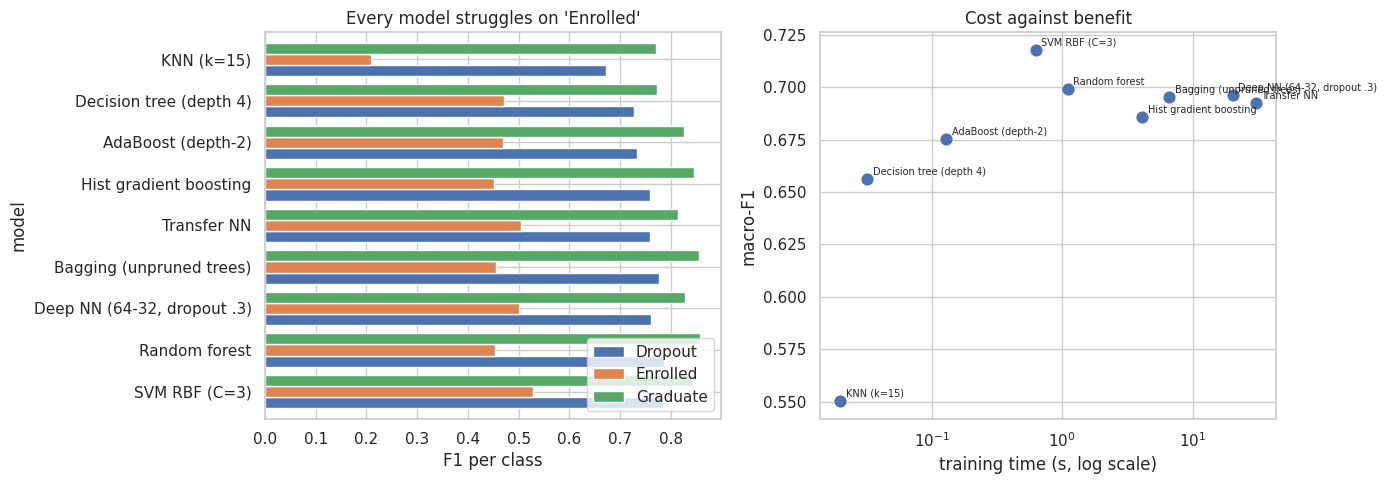

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_df = final.set_index("model")[["f1_dropout", "f1_enrolled", "f1_graduate"]]
plot_df.plot.barh(ax=axes[0], width=.8)
axes[0].set_xlabel("F1 per class"); axes[0].set_title("Every model struggles on 'Enrolled'")
axes[0].legend(["Dropout", "Enrolled", "Graduate"], loc="lower right")

axes[1].scatter(final["fit_s"], final["macro_f1"], s=60)
for _, r in final.iterrows():
    axes[1].annotate(r["model"], (r["fit_s"], r["macro_f1"]), fontsize=7,
                     xytext=(4, 3), textcoords="offset points")
axes[1].set_xscale("log"); axes[1].set_xlabel("training time (s, log scale)")
axes[1].set_ylabel("macro-F1"); axes[1].set_title("Cost against benefit")
plt.tight_layout(); plt.savefig("fig_final.pdf", bbox_inches="tight"); plt.show()

### What the numbers say

**Performance.** The **SVM reaches the best macro-F1 (0.718)** once every model is balanced, and
also the best score on the difficult *Enrolled* class (0.528). The **random forest has the best
accuracy (0.773)** but a lower macro-F1, because it buys accuracy by siding with the majority
class. The gap between the best and worst model is 0.17 macro-F1, and almost all of it is KNN
failing.

**Complexity.** The spread is four orders of magnitude. The random forest stores **450,000 tree
nodes**; the depth-4 tree stores **31** and gives up only 0.06 macro-F1. AdaBoost converges after
**7 stumps, 49 nodes** in total. The SVM keeps **2,134 support vectors**, about 60 % of the
training set, which is a sign that the classes overlap heavily, exactly as the *Enrolled* confusion
suggests.

**Computation time.** Training spans 0.02 s (KNN, which does nothing) to 8.4 s (bagging 300
unpruned trees) and about 20 s for the neural network. Prediction matters more in deployment: the
SVM needs **220 ms** for 885 students because it compares each one against every support vector,
while the decision tree needs **2.4 ms**, a factor of 90.

### Back to the real-world problem

For a semester-end screening run over a few thousand students, none of these times is a
constraint, so the choice should be driven by **what happens to the prediction**:

* If the output feeds a **counsellor's worklist**, the **depth-4 decision tree** is the strongest
  candidate despite being third on macro-F1. It is 31 nodes, reads as a handful of rules about
  approval rates and unpaid tuition, predicts in 2 ms, and a counsellor can explain to a student
  why they were contacted. Accuracy that cannot be acted on is worth less than a rule that can.
* If the output feeds an **automatic ranking** with no human explanation needed, the **SVM** is the
  better choice on pure performance, and the **random forest** if accuracy matters more than the
  minority class.
* The **neural network is not justified here.** It costs the most to train, is the hardest to
  explain, and lands mid-table on macro-F1. Its one advantage is the highest *Enrolled* recall
  (0.60), achieved through class weighting, which any of the other models can also be given.

**The limiting factor is the data, not the algorithm.** Six of the nine models land between 0.675
and 0.718 macro-F1, and every one of them fails on the same class for the same reason: *Enrolled*
students have not yet reached the outcome being predicted. The practical fix is not a better
classifier but a better problem definition, for example predicting dropout within a fixed horizon,
or waiting until the label is settled before training on it.